# Сверточная сеть
В этом ноутбуке мы расширим предыдущий и создадим первую сверточную сеть

In [29]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [30]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist)


In [31]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

In [32]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [33]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

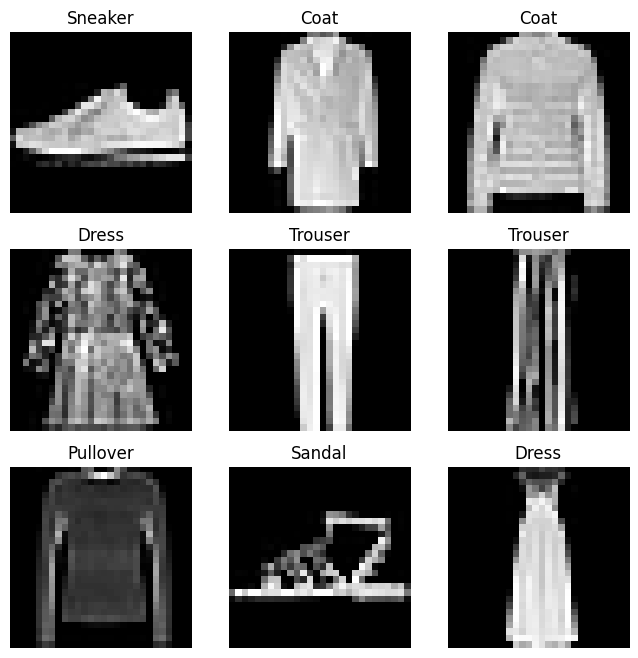

In [34]:
plot_samples(train_data, labels_map, cols=3, rows=3)

In [35]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


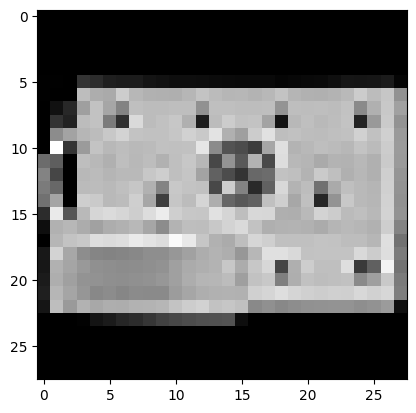

Label: 8


In [36]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [37]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


Теперь создадим класс модели и интстанциируем её. В данном случае это простая сверточная сеть: изображение проходит через блоки из сверток `nn.Conv2d` с batch-нормализацией (`nn.BatchNorm2d`) и активацией (`nn.ReLU`), а затем карта признаков разворачивается в вектор и подается в линейную голову `nn.Linear`, выдающую логиты для 10 классов. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.


### Архитектура модели

Схема ниже показывает названия слоев и размер выхода каждого слоя (для одного изображения):

![diagram](../images/simple_cnn.png)

In [38]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            # your code
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.head = nn.Linear(16*28*28, 10)

    def forward(self, x):
        x = self.base(x)
        # Необходимо превратить вход в вектор, чтобы можно было применить линейный слой

        x = x.view(x.size(0), -1)
        logits = self.head(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (head): Linear(in_features=12544, out_features=10, bias=True)
)


Часто вместо решейпа перед головой используют пулинг. Это специальный слой, который накладывается на вход и позволяет получить его преобразование (max, avg) без весов:
![alt text](..\images\max_pool.png "Stride=1, padding=0")

Если сделать MaxPool2d или AvgPool2d с размером ядра, равным размеру входа, то получится вектор такого же размера, как исходное число каналов. Однако, все равно придется добавить дополнительное измерение.

**Задание**: Измените модель, используя MaxPool или AvgPool вместо view(). Сравните результаты.

In [64]:
class NeuralNetworkPool(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.head = nn.Linear(16*14*14, 10)

    def forward(self, x):
        x = self.base(x)
        x = x.flatten(1)
        logits = self.head(x)
        return logits

In [65]:
model = NeuralNetworkPool().to(device)
print(model)

NeuralNetworkPool(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Linear(in_features=3136, out_features=10, bias=True)
)


Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [66]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [53]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        # Compute prediction error
        preds = model(inputs)
        loss = loss_fn(preds, targets)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            loss, current = loss.item(), (batch_idx + 1) * len(inputs)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


In [89]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0, 0

    num_classes = 10
    cm = torch.zeros(num_classes, num_classes, dtype=torch.long)

    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs)
            loss = loss_fn(preds, targets)
            test_loss += loss.item()

            pred_labels = preds.argmax(1)
            num_correct += (pred_labels == targets).sum().item()

            for t, p in zip(targets.view(-1), pred_labels.view(-1)):
                cm[t.long(), p.long()] += 1

    test_loss /= num_batches

    accuracy = num_correct / size

    precisions, recalls = [], []
    for k in range(num_classes):
        tp = cm[k, k].item()
        fp = cm[:, k].sum().item() - tp
        fn = cm[k, :].sum().item() - tp
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        precisions.append(precision)
        recalls.append(recall)

    macro_p = sum(precisions) / num_classes
    macro_r = sum(recalls) / num_classes

    print(f"\nTest Error:\n")
    print(f"Accuracy: {accuracy*100:.2f}%")
    print(f"Avg loss: {test_loss:.4f}")
    print(f"Macro Precision: {macro_p:.4f}")
    print(f"Macro Recall:    {macro_r:.4f}")

    return test_loss, accuracy, macro_p, macro_r


Задание: Добавьте метрики precision и recall для проверки

In [67]:
best_val_loss = float("inf")
best_state = None

epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)

    val_loss, acc, p, r = test(test_dataloader, model, loss_fn)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"    новый лучший val_loss: {best_val_loss:.4f} (acc={acc*100:.2f}%)")

if best_state is not None:
    model.load_state_dict(best_state)
    print(f"\nВосстановлены веса с best_val_loss = {best_val_loss:.4f}")

Epoch 1
-------------------------------
loss: 2.522098  [   64/60000]
loss: 0.920151  [ 6464/60000]
loss: 0.779222  [12864/60000]
loss: 0.578708  [19264/60000]
loss: 0.509304  [25664/60000]
loss: 0.472724  [32064/60000]
loss: 0.484701  [38464/60000]
loss: 0.531768  [44864/60000]
loss: 0.401796  [51264/60000]
loss: 0.430157  [57664/60000]
Test Error: 

Accuracy: 83.59%
Avg loss: 0.4695
Macro Precision: 0.8352
Macro Recall:    0.8359
    новый лучший val_loss: 0.4695 (acc=83.59%)
Epoch 2
-------------------------------
loss: 0.541694  [   64/60000]
loss: 0.402794  [ 6464/60000]
loss: 0.311366  [12864/60000]
loss: 0.494456  [19264/60000]
loss: 0.214152  [25664/60000]
loss: 0.331150  [32064/60000]
loss: 0.374657  [38464/60000]
loss: 0.522240  [44864/60000]
loss: 0.470735  [51264/60000]
loss: 0.438553  [57664/60000]
Test Error: 

Accuracy: 86.13%
Avg loss: 0.4077
Macro Precision: 0.8605
Macro Recall:    0.8613
    новый лучший val_loss: 0.4077 (acc=86.13%)
Epoch 3
--------------------------

Осталось сохранить модель для дальнейшего использования.

Задание: придумайте свою собственную модель, на следующем занятии сравнимся, у кого получилось достичь наилучших результатов.

In [92]:
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.head(self.base(x))


In [91]:
model = MyModel().to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)

best_val_loss = float("inf")
best_state = None

epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)

    val_loss, acc, p, r = test(test_dataloader, model, loss_fn)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"    новый лучший val_loss: {best_val_loss:.4f} (acc={acc*100:.2f}%)")

if best_state is not None:
    model.load_state_dict(best_state)
    print(f"\nВосстановлены веса с best_val_loss = {best_val_loss:.4f}")

Epoch 1
-------------------------------
loss: 2.345526  [   64/60000]
loss: 0.635529  [ 6464/60000]
loss: 0.498163  [12864/60000]
loss: 0.397471  [19264/60000]
loss: 0.353328  [25664/60000]
loss: 0.679364  [32064/60000]
loss: 0.328952  [38464/60000]
loss: 0.217758  [44864/60000]
loss: 0.390342  [51264/60000]
loss: 0.146089  [57664/60000]

Test Error:

Accuracy: 83.36%
Avg loss: 0.4461
Macro Precision: 0.8617
Macro Recall:    0.8336
    новый лучший val_loss: 0.4461 (acc=83.36%)
Epoch 2
-------------------------------
loss: 0.500677  [   64/60000]
loss: 0.296158  [ 6464/60000]
loss: 0.269375  [12864/60000]
loss: 0.360001  [19264/60000]
loss: 0.323569  [25664/60000]
loss: 0.249070  [32064/60000]
loss: 0.263032  [38464/60000]
loss: 0.413758  [44864/60000]
loss: 0.154595  [51264/60000]
loss: 0.385287  [57664/60000]

Test Error:

Accuracy: 88.60%
Avg loss: 0.3021
Macro Precision: 0.8907
Macro Recall:    0.8860
    новый лучший val_loss: 0.3021 (acc=88.60%)
Epoch 3
--------------------------